# Mexican drug trafficking association network

Each annual graph is an **undirected, unweighted bipartite network**: municipality nodes connect to organization/category nodes when the CSV entry equals 1. Edges represent reported associations, not proof of territorial control or cooperation. `Otros` is retained as an aggregate category, not interpreted as one cartel.

`networks_by_year` stores all annual snapshots. **`net` is the 2010 snapshot** by default; change `selected_year` to explore another year. All municipalities recorded in that year and all ten categories are included, even when isolated. Years are not pooled.

Explicit annual variables `net_1990` through `net_2010` reference the same graphs as `networks_by_year`.

In [1]:
from pathlib import Path

import pandas as pd
import networkx as nx
from networkx.algorithms import bipartite
from IPython.display import display

# Run the notebook with its containing directory as the working directory.
data = pd.read_csv(
    Path("CosciaRios2012_DataBase.csv"),
    dtype={"Code": "string", "State": "string"},
)
organization_columns = data.columns.drop(["Code", "State", "Year"]).tolist()
assert not data.isna().any().any(), "Missing values require inspection."
assert not data.duplicated(["Code", "Year"]).any(), "Duplicate municipality-year rows."
assert data[organization_columns].isin([0, 1]).all().all(), "Expected binary associations."

print(f"Records: {len(data):,}")
print(f"Years: {data['Year'].min()}–{data['Year'].max()}")
print(f"Distinct municipalities: {data['Code'].nunique():,}")
print(f"Organization/category columns: {len(organization_columns)}")

Records: 51,596
Years: 1990–2010
Distinct municipalities: 2,457
Organization/category columns: 10


In [2]:
def build_annual_network(year_data, year):
    graph = nx.Graph(year=int(year))
    # Prefixes prevent collisions between municipality and organization identifiers.
    graph.add_nodes_from(
        (f"organization:{name}", {"bipartite": 1, "node_type": "organization", "label": name})
        for name in organization_columns
    )
    for _, row in year_data.iterrows():
        municipality = f"municipality:{row['Code']}"
        graph.add_node(
            municipality, bipartite=0, node_type="municipality",
            code=row["Code"], state=row["State"], label=row["Code"],
        )
        graph.add_edges_from(
            (municipality, f"organization:{name}")
            for name in organization_columns if row[name] == 1
        )
    return graph

networks_by_year = {
    int(year): build_annual_network(year_data, year)
    for year, year_data in data.groupby("Year", sort=True)
}
net_1990 = networks_by_year[1990]
net_1991 = networks_by_year[1991]
net_1992 = networks_by_year[1992]
net_1993 = networks_by_year[1993]
net_1994 = networks_by_year[1994]
net_1995 = networks_by_year[1995]
net_1996 = networks_by_year[1996]
net_1997 = networks_by_year[1997]
net_1998 = networks_by_year[1998]
net_1999 = networks_by_year[1999]
net_2000 = networks_by_year[2000]
net_2001 = networks_by_year[2001]
net_2002 = networks_by_year[2002]
net_2003 = networks_by_year[2003]
net_2004 = networks_by_year[2004]
net_2005 = networks_by_year[2005]
net_2006 = networks_by_year[2006]
net_2007 = networks_by_year[2007]
net_2008 = networks_by_year[2008]
net_2009 = networks_by_year[2009]
net_2010 = networks_by_year[2010]

selected_year = 2010
net = networks_by_year[selected_year]
municipality_nodes = {n for n, attrs in net.nodes(data=True) if attrs["bipartite"] == 0}
organization_nodes = set(net) - municipality_nodes

assert nx.is_bipartite(net)
assert all(net.nodes[u]["bipartite"] != net.nodes[v]["bipartite"] for u, v in net.edges())
print(f"net: {selected_year} annual snapshot")

net: 2010 annual snapshot


## Basic statistics

Standard NetworkX density uses all possible pairs of nodes. Bipartite density instead uses only possible municipality–organization pairs, making it more informative here. Average degree includes isolated nodes; active municipalities have at least one reported association. Clustering below is ordinary triangle clustering, which is necessarily zero in a bipartite graph.

Distances are reported only within the largest connected component because disconnected networks have no finite overall average shortest path.

In [3]:
def basic_stats(graph):
    municipalities = {n for n, attrs in graph.nodes(data=True) if attrs["bipartite"] == 0}
    organizations = set(graph) - municipalities
    components = list(nx.connected_components(graph))
    largest = max(components, key=len, default=set())
    n, m = graph.number_of_nodes(), graph.number_of_edges()
    return {
        "nodes": n,
        "municipalities": len(municipalities),
        "organization_categories": len(organizations),
        "edges": m,
        "active_municipalities": sum(graph.degree(v) > 0 for v in municipalities),
        "active_organization_categories": sum(graph.degree(v) > 0 for v in organizations),
        "isolates": nx.number_of_isolates(graph),
        "connected_components": len(components),
        "largest_component_nodes": len(largest),
        "average_degree": 2 * m / n if n else 0,
        "density": nx.density(graph),
        "bipartite_density": bipartite.density(graph, municipalities),
    }

stats = pd.Series(basic_stats(net), name=selected_year)
display(stats.to_frame("value"))

largest_component = net.subgraph(max(nx.connected_components(net), key=len)).copy()
print(f"Bipartite: {nx.is_bipartite(net)}")
print(f"Connected: {nx.is_connected(net)}")
print(f"Average triangle clustering: {nx.average_clustering(net):.3f}")
print(f"Largest component diameter: {nx.diameter(largest_component)}")
print(
    "Largest component average shortest path length: "
    f"{nx.average_shortest_path_length(largest_component):.3f}"
)

Bipartite: True
Connected: False
Average triangle clustering: 0.000
Largest component diameter: 4
Largest component average shortest path length: 2.888


,value
nodes,2466.000000
municipalities,2456.000000
organization_categories,10.000000
edges,1486.000000
active_municipalities,709.000000
active_organization_categories,10.000000
isolates,1747.000000
connected_components,1748.000000
largest_component_nodes,719.000000
average_degree,1.205191


In [4]:
# Organization degree is the number of associated municipalities in this year.
organization_degrees = pd.DataFrame([
    {"organization_category": net.nodes[node]["label"], "municipalities": net.degree(node)}
    for node in organization_nodes
]).sort_values(["municipalities", "organization_category"], ascending=[False, True]).reset_index(drop=True)
display(organization_degrees)

# Municipality degree is the number of associated organization categories.
municipality_degree_counts = pd.Series(
    [net.degree(node) for node in municipality_nodes], name="municipalities"
).value_counts().sort_index().rename_axis("organization_categories")
display(municipality_degree_counts.to_frame())

,organization_category,municipalities
0,Zetas,405
1,Golfo,244
2,Familia,227
3,Sinaloa,176
4,Beltran_Leyva,157
5,Juarez,74
6,Beltran_Leyva_Family,57
7,Otros,54
8,Sinaloa_Family,53
9,Tijuana,39


,count
organization_categories,
0,1747
1,271
2,261
3,86
4,50
5,22
6,11
7,6
8,1


In [5]:
annual_stats = pd.DataFrame.from_dict(
    {year: basic_stats(graph) for year, graph in networks_by_year.items()},
    orient="index",
).rename_axis("year")
display(annual_stats)
print(f"Mean annual nodes: {annual_stats['nodes'].mean():,.1f}")
print(f"Mean annual edges: {annual_stats['edges'].mean():,.1f}")
print(f"Total associations across municipality-year records: {annual_stats['edges'].sum():,}")

Mean annual nodes: 2,467.0
Mean annual edges: 296.6
Total associations across municipality-year records: 6,228


,nodes,municipalities,organization_categories,edges,active_municipalities,active_organization_categories,isolates,connected_components,largest_component_nodes,average_degree,density,bipartite_density
year,,,,,,,,,,,,
1990,2467,2457,10,0,0,0,2467,2467,1,0.000000,0.000000,0.000000
1991,2467,2457,10,6,6,2,2459,2461,4,0.004864,0.000002,0.000244
1992,2467,2457,10,6,5,3,2459,2461,6,0.004864,0.000002,0.000244
1993,2467,2457,10,24,22,5,2440,2443,15,0.019457,0.000008,0.000977
1994,2467,2457,10,31,29,4,2434,2436,30,0.025132,0.000010,0.001262
1995,2467,2457,10,23,20,4,2443,2445,16,0.018646,0.000008,0.000936
1996,2467,2457,10,36,31,6,2430,2432,35,0.029185,0.000012,0.001465
1997,2467,2457,10,51,48,6,2413,2417,25,0.041346,0.000017,0.002076
1998,2467,2457,10,49,43,5,2419,2420,48,0.039724,0.000016,0.001994


## 2010 network plot

Orange nodes represent organization categories; blue nodes represent municipalities. All active nodes appear in the main panel; all isolated municipalities appear separately for readability. Only organization categories are labeled. Layout positions represent network structure, not geography; isolate positions are arbitrary.

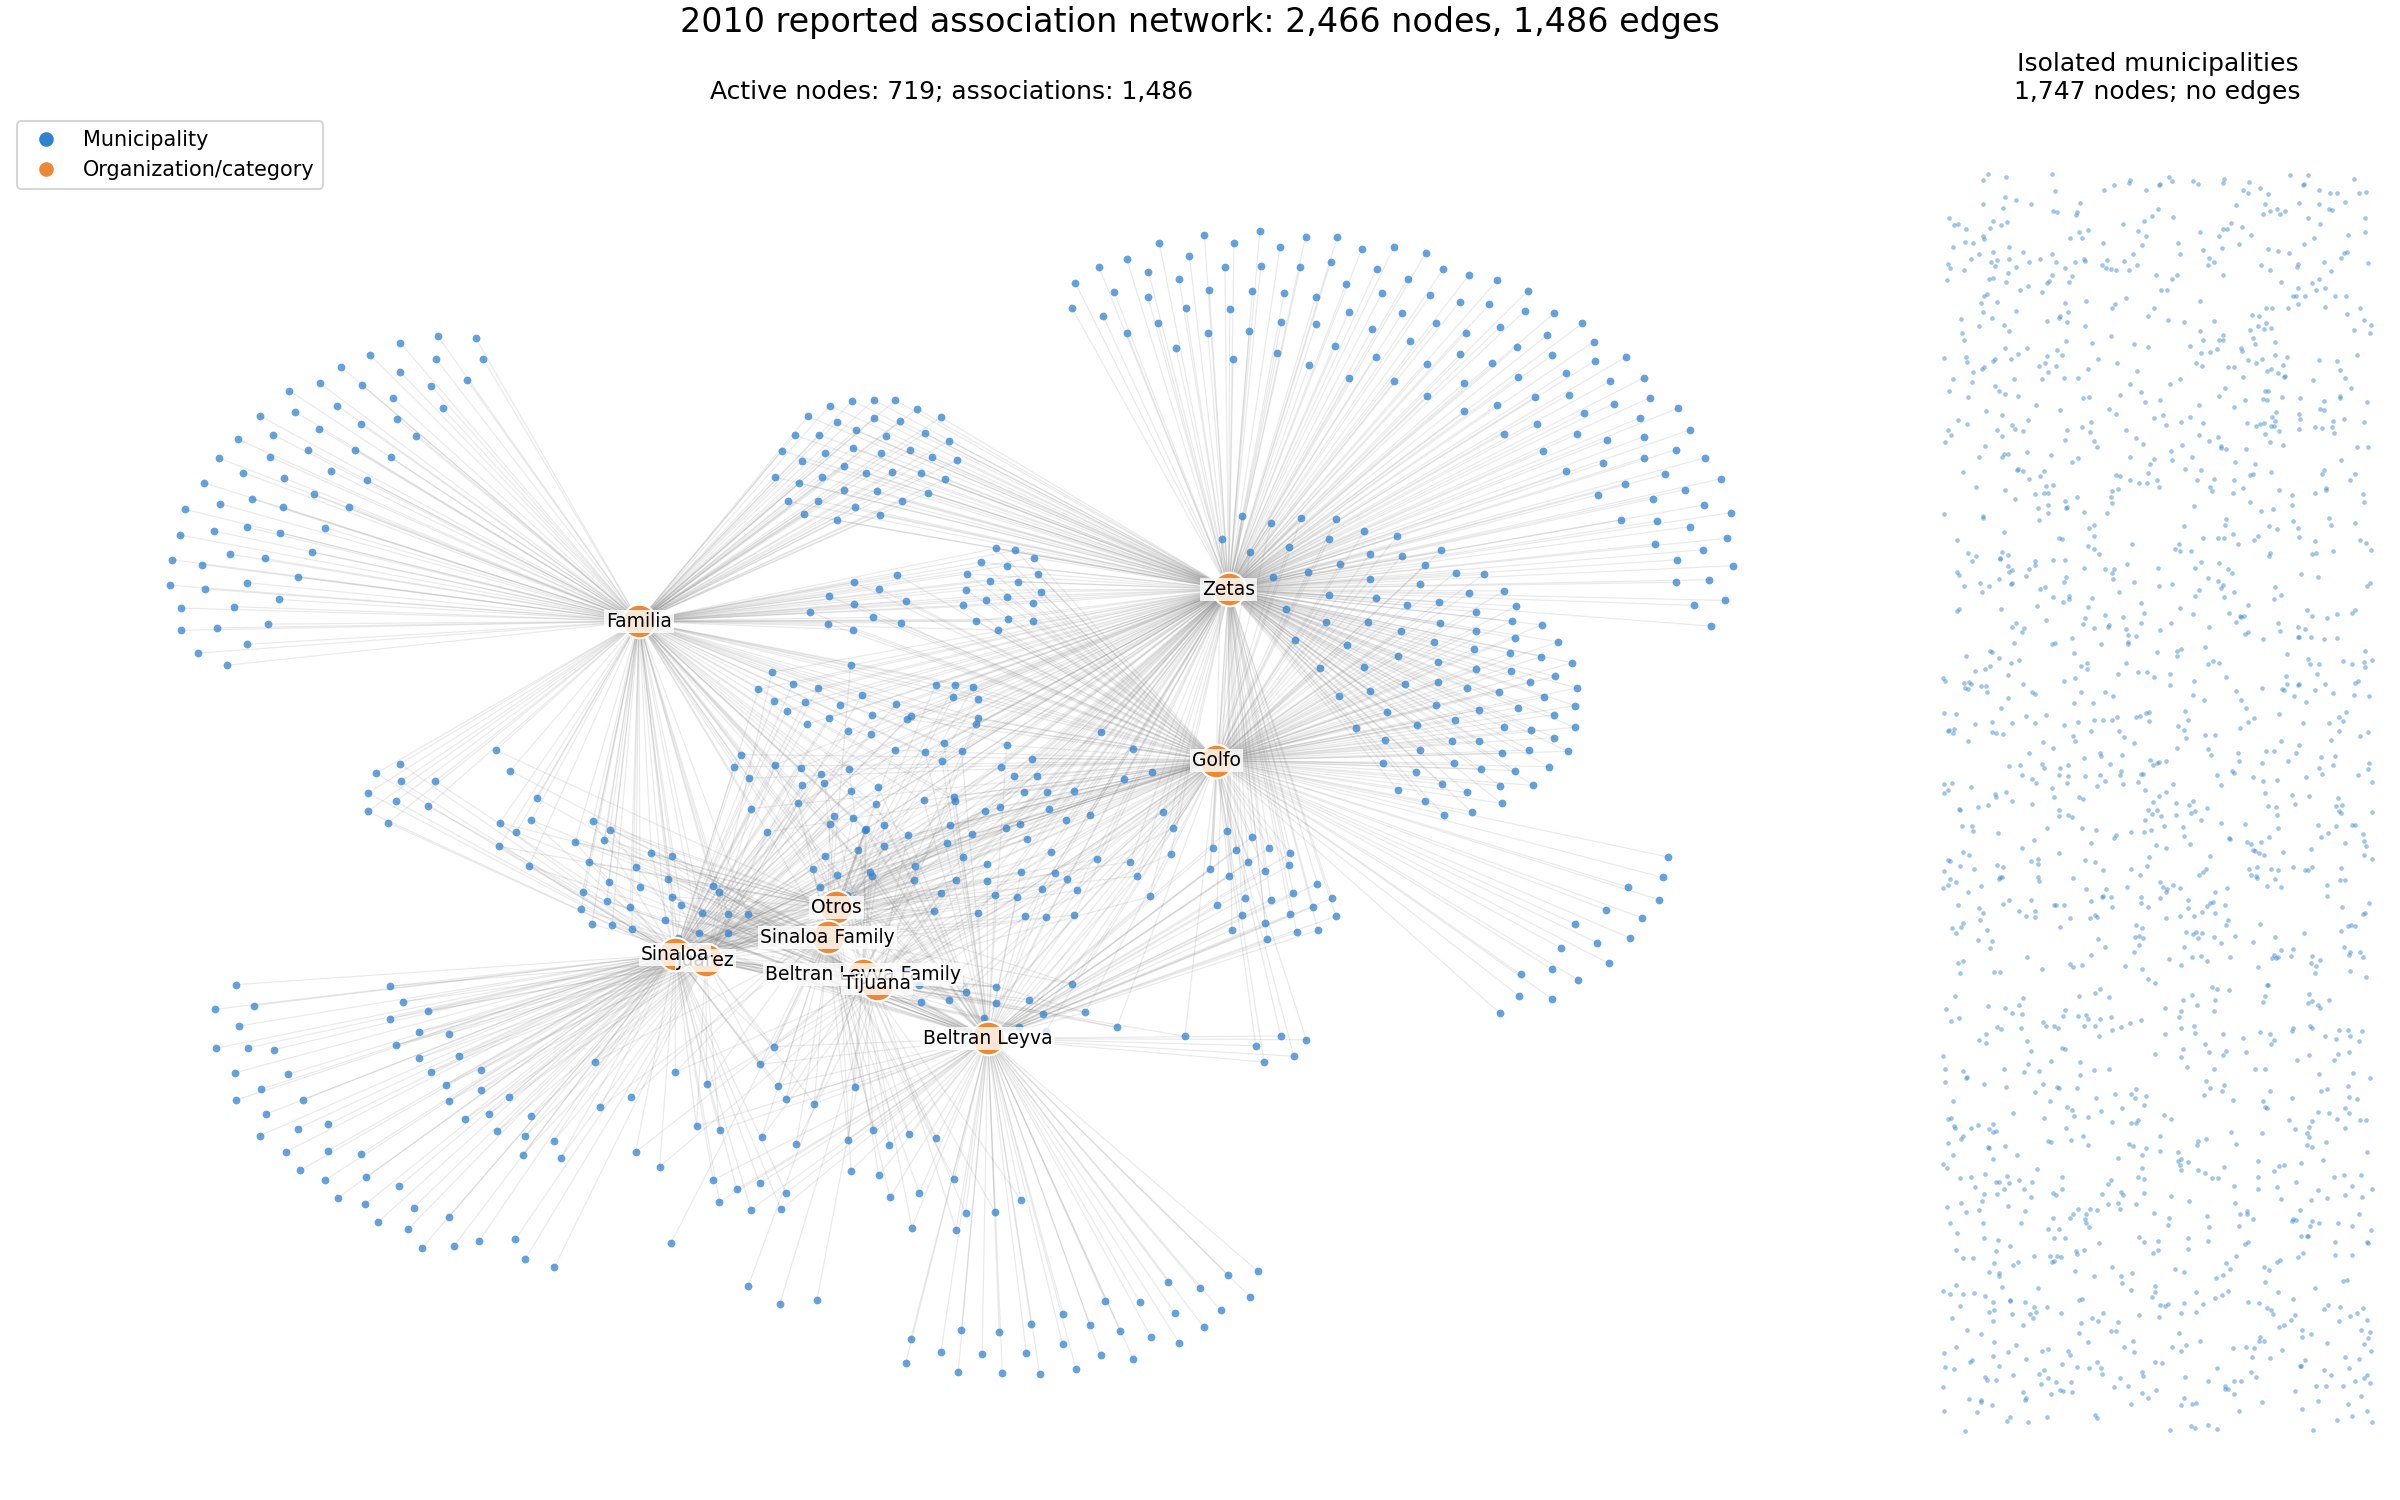

In [6]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from IPython.display import Image
from io import BytesIO

plot_net = net_2010
isolates = list(nx.isolates(plot_net))
active = plot_net.subgraph([n for n in plot_net if plot_net.degree(n) > 0])
organizations = sorted(n for n in active if active.nodes[n]["bipartite"] == 1)
municipalities = sorted(set(active) - set(organizations))
pos = nx.spring_layout(active, seed=42, iterations=150)
fig, (ax, ax_isolates) = plt.subplots(1, 2, figsize=(16, 10),
    gridspec_kw={"width_ratios": [4, 1]}, constrained_layout=True)
nx.draw_networkx_edges(active, pos, ax=ax, edge_color="gray", alpha=0.16, width=0.6)
nx.draw_networkx_nodes(active, pos, nodelist=municipalities, ax=ax,
    node_color="#3182ce", node_size=14, alpha=0.75, linewidths=0)
nx.draw_networkx_nodes(active, pos, nodelist=organizations, ax=ax,
    node_color="#ed8936", node_size=260, edgecolors="white")
nx.draw_networkx_labels(active, pos, ax=ax, font_size=9,
    labels={n: active.nodes[n]["label"].replace("_", " ") for n in organizations},
    bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none", "pad": 1})
ax.set_title(f"Active nodes: {len(active):,}; associations: {active.number_of_edges():,}")
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", color=color, label=label)
    for color, label in [("#3182ce", "Municipality"), ("#ed8936", "Organization/category")]],
    loc="upper left")
ax.axis("off")
rng = np.random.default_rng(42)
isolate_pos = dict(zip(isolates, rng.random((len(isolates), 2))))
nx.draw_networkx_nodes(plot_net, isolate_pos, nodelist=isolates, ax=ax_isolates,
    node_color="#3182ce", node_size=5, alpha=0.45, linewidths=0)
ax_isolates.set_title(f"Isolated municipalities\n{len(isolates):,} nodes; no edges")
ax_isolates.axis("off")
fig.suptitle(f"2010 reported association network: {len(plot_net):,} nodes, "
    f"{plot_net.number_of_edges():,} edges", fontsize=16)
# Embed the plot without creating a separate image file.
plot_buffer = BytesIO()
fig.savefig(plot_buffer, format="png", dpi=150)
plt.close(fig)
display(Image(data=plot_buffer.getvalue()))

## Descriptive statistics for the presentation

Describe recorded associations rather than territorial control. Organization degree measures associated municipalities; municipality degree measures associated organization categories. Municipality overlap means at least two categories are recorded in the same municipality, not evidence of cooperation or rivalry.

Coverage and edge turnover are reported separately. Turnover comparisons use only municipalities recorded in **both adjacent years**, so entering or leaving the file does not automatically count as link formation or disappearance. “Appearing” means absent in the previous snapshot, including possible reappearances. The first year has no previous snapshot and therefore no turnover estimate.

In [7]:
# Add presentation measures to the annual summary.
for year, graph in networks_by_year.items():
    municipalities = [n for n in graph if graph.nodes[n]["bipartite"] == 0]
    degrees = [graph.degree(n) for n in municipalities]
    active_count = sum(d > 0 for d in degrees)
    overlap_count = sum(d >= 2 for d in degrees)
    annual_stats.loc[year, "active_municipality_percentage"] = 100 * active_count / len(municipalities)
    annual_stats.loc[year, "overlapping_municipalities"] = overlap_count
    annual_stats.loc[year, "overlap_percentage_among_active"] = 100 * overlap_count / active_count if active_count else 0
    annual_stats.loc[year, "mean_degree_active_municipalities"] = sum(degrees) / active_count if active_count else 0

def municipality_set(graph):
    return {n for n, attrs in graph.nodes(data=True) if attrs["bipartite"] == 0}

def association_set(graph, municipalities):
    return {(municipality, organization)
            for municipality in municipalities for organization in graph.neighbors(municipality)}

turnover_records = []
years = sorted(networks_by_year)
for previous_year, year in zip(years[:-1], years[1:]):
    previous_graph, current_graph = networks_by_year[previous_year], networks_by_year[year]
    previous_municipalities = municipality_set(previous_graph)
    current_municipalities = municipality_set(current_graph)
    shared = previous_municipalities & current_municipalities
    previous_edges = association_set(previous_graph, shared)
    current_edges = association_set(current_graph, shared)
    turnover_records.append({
        "year": year,
        "shared_municipalities": len(shared),
        "municipalities_entering_file": len(current_municipalities - previous_municipalities),
        "municipalities_leaving_file": len(previous_municipalities - current_municipalities),
        "appearing_associations": len(current_edges - previous_edges),
        "persisting_associations": len(current_edges & previous_edges),
        "disappearing_associations": len(previous_edges - current_edges),
        "associations_in_entering_municipalities": len(association_set(current_graph, current_municipalities - previous_municipalities)),
        "associations_in_leaving_municipalities": len(association_set(previous_graph, previous_municipalities - current_municipalities)),
    })
turnover_stats = pd.DataFrame(turnover_records).set_index("year")
display(annual_stats)
display(turnover_stats)

# Named variables used in the presentation.
dataset_summary = {
    "First year": min(years), "Last year": max(years), "Annual snapshots": len(years),
    "Municipality-year records": len(data), "Distinct municipalities across all years": data["Code"].nunique(),
    "Organization categories": len(organization_columns),
    "Total associations across all years": int(annual_stats["edges"].sum()),
    "Mean annual nodes": annual_stats["nodes"].mean(),
    "Mean annual edges": annual_stats["edges"].mean(),
}
snapshot_2010_stats = basic_stats(net_2010)
snapshot_2010_stats.update({
    name: annual_stats.loc[2010, name]
    for name in ["active_municipality_percentage", "overlapping_municipalities",
                 "overlap_percentage_among_active", "mean_degree_active_municipalities"]
})
component_2010 = net_2010.subgraph(max(nx.connected_components(net_2010), key=len))
snapshot_2010_stats["largest_component_diameter"] = nx.diameter(component_2010)
snapshot_2010_stats["largest_component_mean_shortest_path"] = nx.average_shortest_path_length(component_2010)
organization_degrees_2010 = pd.Series({net_2010.nodes[n]["label"]: net_2010.degree(n)
    for n in net_2010 if net_2010.nodes[n]["bipartite"] == 1}).sort_values(ascending=False)
municipality_degree_counts_2010 = pd.Series([net_2010.degree(n) for n in municipality_set(net_2010)]
    ).value_counts().sort_index().rename_axis("organization_categories")

,nodes,municipalities,organization_categories,edges,active_municipalities,active_organization_categories,isolates,connected_components,largest_component_nodes,average_degree,density,bipartite_density,active_municipality_percentage,overlapping_municipalities,overlap_percentage_among_active,mean_degree_active_municipalities
year,,,,,,,,,,,,,,,,
1990,2467,2457,10,0,0,0,2467,2467,1,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
1991,2467,2457,10,6,6,2,2459,2461,4,0.004864,0.000002,0.000244,0.244200,0.0,0.000000,1.000000
1992,2467,2457,10,6,5,3,2459,2461,6,0.004864,0.000002,0.000244,0.203500,1.0,20.000000,1.200000
1993,2467,2457,10,24,22,5,2440,2443,15,0.019457,0.000008,0.000977,0.895401,2.0,9.090909,1.090909
1994,2467,2457,10,31,29,4,2434,2436,30,0.025132,0.000010,0.001262,1.180301,2.0,6.896552,1.068966
1995,2467,2457,10,23,20,4,2443,2445,16,0.018646,0.000008,0.000936,0.814001,3.0,15.000000,1.150000
1996,2467,2457,10,36,31,6,2430,2432,35,0.029185,0.000012,0.001465,1.261701,5.0,16.129032,1.161290
1997,2467,2457,10,51,48,6,2413,2417,25,0.041346,0.000017,0.002076,1.953602,3.0,6.250000,1.062500
1998,2467,2457,10,49,43,5,2419,2420,48,0.039724,0.000016,0.001994,1.750102,6.0,13.953488,1.139535


,shared_municipalities,municipalities_entering_file,municipalities_leaving_file,appearing_associations,persisting_associations,disappearing_associations,associations_in_entering_municipalities,associations_in_leaving_municipalities
year,,,,,,,,
1991,2457,0,0,6,0,0,0,0
1992,2457,0,0,6,0,6,0,0
1993,2457,0,0,21,3,3,0,0
1994,2457,0,0,25,6,18,0,0
1995,2457,0,0,15,8,23,0,0
1996,2457,0,0,28,8,15,0,0
1997,2457,0,0,42,9,27,0,0
1998,2457,0,0,37,12,39,0,0
1999,2457,0,0,24,7,42,0,0


## Presentation figures

Counts show changes in recorded coverage and associations. Turnover is restricted to shared municipalities. `Otros` remains an aggregate category. Figures are embedded in the notebook; no separate files are saved.

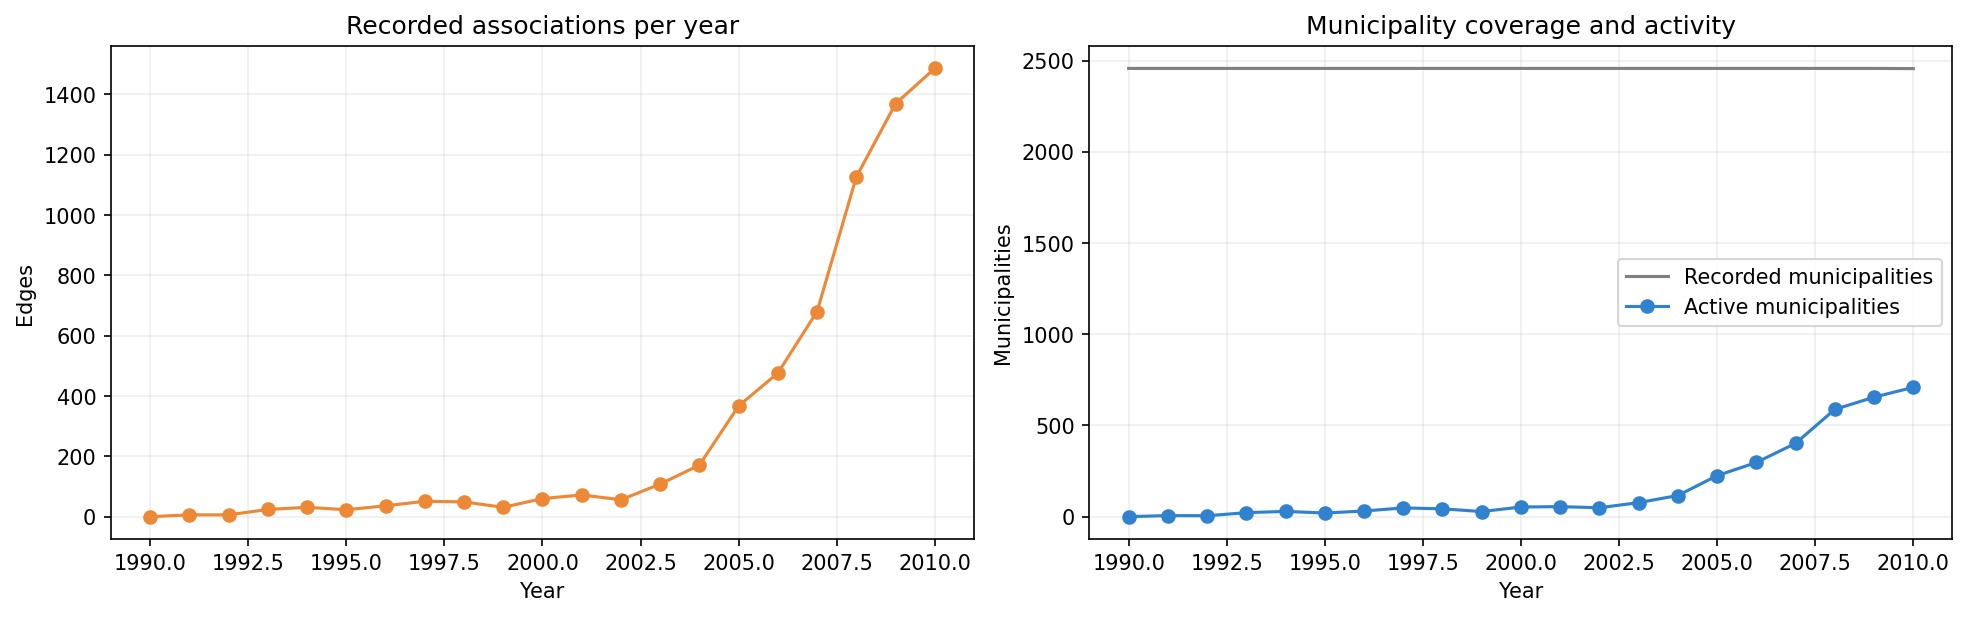

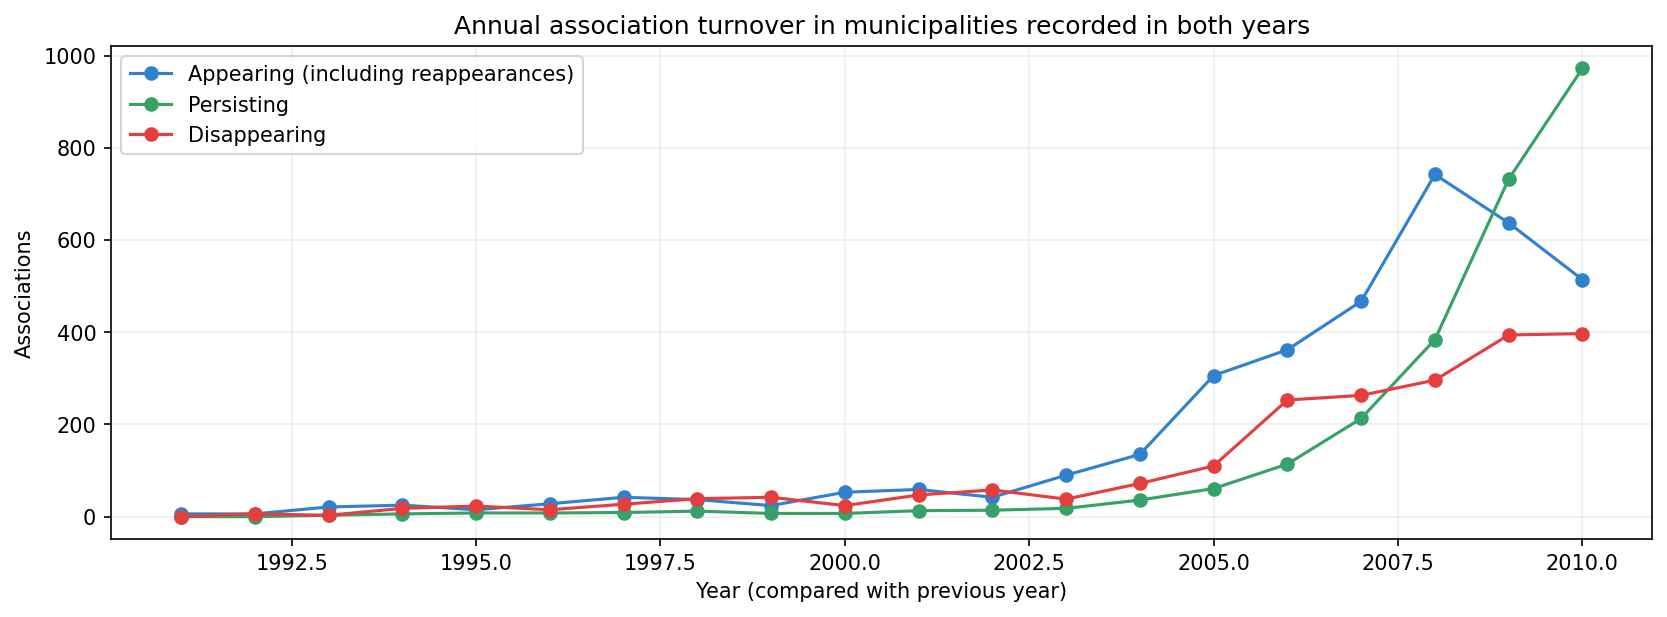

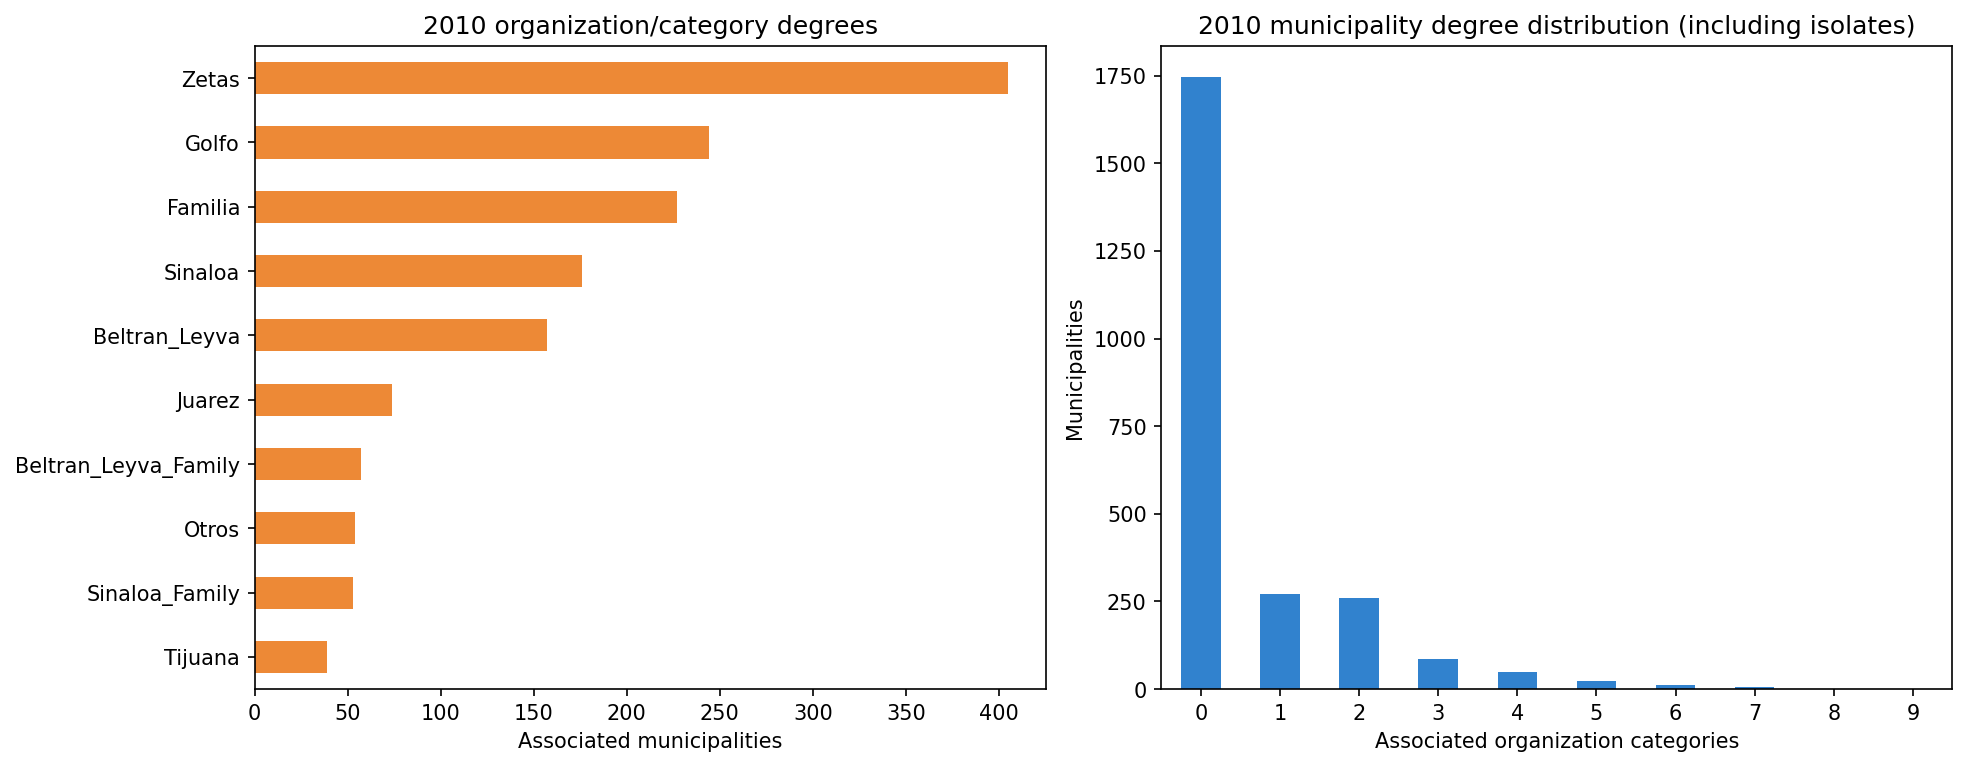

In [8]:
def show_presentation_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
axes[0].plot(annual_stats.index, annual_stats["edges"], marker="o", color="#ed8936")
axes[0].set(title="Recorded associations per year", xlabel="Year", ylabel="Edges")
axes[1].plot(annual_stats.index, annual_stats["municipalities"], label="Recorded municipalities", color="gray")
axes[1].plot(annual_stats.index, annual_stats["active_municipalities"], marker="o", label="Active municipalities", color="#3182ce")
axes[1].set(title="Municipality coverage and activity", xlabel="Year", ylabel="Municipalities")
axes[1].legend()
for ax in axes: ax.grid(alpha=0.2)
show_presentation_figure(fig)

fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
for column, label, color in [
    ("appearing_associations", "Appearing (including reappearances)", "#3182ce"),
    ("persisting_associations", "Persisting", "#38a169"),
    ("disappearing_associations", "Disappearing", "#e53e3e"),
]:
    ax.plot(turnover_stats.index, turnover_stats[column], marker="o", label=label, color=color)
ax.set(title="Annual association turnover in municipalities recorded in both years",
       xlabel="Year (compared with previous year)", ylabel="Associations")
ax.legend()
ax.grid(alpha=0.2)
show_presentation_figure(fig)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
organization_degrees_2010.sort_values().plot.barh(ax=axes[0], color="#ed8936")
axes[0].set(title="2010 organization/category degrees", xlabel="Associated municipalities", ylabel="")
municipality_degree_counts_2010.plot.bar(ax=axes[1], color="#3182ce", rot=0)
axes[1].set(title="2010 municipality degree distribution (including isolates)",
    xlabel="Associated organization categories", ylabel="Municipalities")
show_presentation_figure(fig)

## Presentation values: Name : value

The following cell prints every numerical descriptive measure used above, including the full annual and turnover tables. Percentages use a 0–100 scale. Graph objects, layout coordinates, and temporary plotting variables are not presentation statistics.

In [9]:
def print_presentation_value(name, value):
    if isinstance(value, (int, np.integer)):
        formatted = str(value)
    elif isinstance(value, (float, np.floating)):
        formatted = str(int(value)) if float(value).is_integer() else f"{value:.6g}"
    else:
        formatted = str(value)
    print(f"{name} : {formatted}")

for name, value in dataset_summary.items():
    print_presentation_value(name, value)
for name, value in snapshot_2010_stats.items():
    print_presentation_value(f"2010 {name.replace('_', ' ')}", value)
for organization, degree in organization_degrees_2010.items():
    print_presentation_value(f"2010 {organization} degree", degree)
for degree, count in municipality_degree_counts_2010.items():
    print_presentation_value(f"2010 municipalities with degree {degree}", count)
for year, row in annual_stats.iterrows():
    for name, value in row.items():
        print_presentation_value(f"{year} {name.replace('_', ' ')}", value)
for year, row in turnover_stats.iterrows():
    for name, value in row.items():
        print_presentation_value(f"{year} {name.replace('_', ' ')}", value)

First year : 1990
Last year : 2010
Annual snapshots : 21
Municipality-year records : 51596
Distinct municipalities across all years : 2457
Organization categories : 10
Total associations across all years : 6228
Mean annual nodes : 2466.95
Mean annual edges : 296.571
2010 nodes : 2466
2010 municipalities : 2456
2010 organization categories : 10
2010 edges : 1486
2010 active municipalities : 709
2010 active organization categories : 10
2010 isolates : 1747
2010 connected components : 1748
2010 largest component nodes : 719
2010 average degree : 1.20519
2010 density : 0.000488921
2010 bipartite density : 0.0605049
2010 active municipality percentage : 28.8681
2010 overlapping municipalities : 438
2010 overlap percentage among active : 61.7772
2010 mean degree active municipalities : 2.09591
2010 largest component diameter : 4
2010 largest component mean shortest path : 2.88777
2010 Zetas degree : 405
2010 Golfo degree : 244
2010 Familia degree : 227
2010 Sinaloa degree : 176
2010 Beltran_

# Research question

**Can historical network structures predict the formation of new cartel–municipality connections, and what patterns explain their emergence?**

The measured outcome is a newly recorded association, not confirmed criminal expansion. Main analysis: pairs absent at year t, predicting presence at t+1, including reappearances. Sensitivity analyses restrict to first observed associations and exclude `Otros`.

Only municipalities recorded in both adjacent years are evaluated. Organizations become eligible after their first observed association anywhere in the historical data; we do not claim to predict the emergence of previously unobserved organizations. Excluded positives are counted. The dataset's category definitions are retrospective, which limits a strictly prospective interpretation.

Development evaluation predicts 2007–2008; final evaluation predicts 2009–2010. Models and features are fixed before examining final results. Each fold trains only on outcomes from earlier years, starting in 2000. No random row split or final-year tuning is used. Historical inactivity is not proof of true absence.

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from statsmodels.genmod.generalized_linear_model import GLM
from statsmodels.genmod.families import Binomial

# Fixed node indexing makes annual matrices and historical records comparable.
municipality_codes = sorted(data["Code"].unique())
code_index = {value: i for i, value in enumerate(municipality_codes)}
org_index = {value: i for i, value in enumerate(organization_columns)}
matrices, recorded_codes = {}, {}
for year, rows in data.groupby("Year"):
    matrix = np.zeros((len(municipality_codes), len(organization_columns)), dtype=np.int32)
    indexes = rows["Code"].map(code_index).to_numpy()
    matrix[indexes] = rows[organization_columns].to_numpy(dtype=np.int32)
    matrices[int(year)] = matrix
    recorded_codes[int(year)] = set(rows["Code"])
state_by_code = data.drop_duplicates("Code").set_index("Code")["State"].to_dict()

last_seen = np.full_like(matrices[min(years)], -1)
previous_matrix = np.zeros_like(last_seen)
research_frames, eligibility_records = [], []
for year in years[:-1]:
    current, following = matrices[year], matrices[year + 1]
    last_seen[current == 1] = year
    eligible_orgs = (last_seen >= 0).any(axis=0)
    shared_indexes = np.array([code_index[c] for c in sorted(recorded_codes[year] & recorded_codes[year + 1])])
    candidate_mask = (current[shared_indexes] == 0) & eligible_orgs[None, :]
    local_m, org = np.where(candidate_mask)
    municipality = shared_indexes[local_m]
    # Count length-three walks. For an absent pair, these are length-three paths.
    three_paths = current @ (current.T @ current)
    municipality_degree, organization_degree = current.sum(axis=1), current.sum(axis=0)
    prior_m_degree, prior_o_degree = previous_matrix.sum(axis=1), previous_matrix.sum(axis=0)
    had_previous = last_seen[municipality, org] >= 0
    frame = pd.DataFrame({
        "prediction_year": year + 1,
        "municipality": [municipality_codes[i] for i in municipality],
        "organization": [organization_columns[i] for i in org],
        "new_link": following[municipality, org],
        "previous_association": had_previous.astype(int),
        "years_since_previous": np.where(had_previous, year - last_seen[municipality, org], 0),
        "municipality_degree": municipality_degree[municipality],
        "organization_degree": organization_degree[org],
        "three_step_paths": three_paths[municipality, org],
        "municipality_degree_change": municipality_degree[municipality] - prior_m_degree[municipality],
        "organization_degree_change": organization_degree[org] - prior_o_degree[org],
    })
    frame["state"] = frame["municipality"].map(state_by_code)
    for feature in ["municipality_degree", "organization_degree", "three_step_paths"]:
        frame[f"log_{feature}"] = np.log1p(frame[feature])
    research_frames.append(frame)
    eligibility_records.append({"prediction_year": year + 1, "eligible_pairs": len(frame),
        "new_links": int(frame["new_link"].sum()),
        "positives_excluded_unobserved_organization": int(((current[shared_indexes] == 0) & (following[shared_indexes] == 1) & ~eligible_orgs[None, :]).sum())})
    previous_matrix = current
research_data = pd.concat(research_frames, ignore_index=True)
eligibility_summary = pd.DataFrame(eligibility_records).set_index("prediction_year")
display(eligibility_summary)

# Every candidate is absent at t; all features use t or earlier.
assert (research_data["years_since_previous"] >= 0).all()
assert not research_data.duplicated(["prediction_year", "municipality", "organization"]).any()
assert (research_data["three_step_paths"] >= 0).all()
print(f"Candidate pair-year observations: {len(research_data):,}")

Candidate pair-year observations: 334,314


,eligible_pairs,new_links,positives_excluded_unobserved_organization
prediction_year,,,
1991,0,0,6
1992,4908,1,5
1993,9822,19,2
1994,12261,25,0
1995,12254,15,0
1996,12262,27,1
1997,14706,41,1
1998,17148,37,0
1999,17150,24,0


## Temporal prediction and baselines

Average precision (AP) evaluates rankings under class imbalance. The constant-score baseline has AP equal to the observed link-formation rate. Precision@100 and recall@100 summarize the first 100 ranked candidates, breaking ties by municipality and organization identifier.

Compare municipality degree, degree product, a history/organization model, and that same model plus structural features. Logistic models use ordinary unweighted likelihood with fixed regularization (`C=1`); preprocessing is fit separately on each training fold. Sensitivity comparisons use the same filtered candidate population for every model. First observed means not previously observed in this file, not necessarily genuinely new.

State-block bootstrap intervals quantify variation across geographical groups in the final-year test sample, conditional on trained models. They do not capture all temporal/network dependence or uncertainty from retraining.

For the constant baseline, precision@100 and recall@100 are the expected values under random selection rather than values from arbitrary identifier-based ties. Final evaluation uses rolling retraining: 2009 outcomes become available when predicting 2010. No model settings change between folds.

In [11]:
history_features = ["previous_association", "years_since_previous"]
network_features = ["log_municipality_degree", "log_organization_degree", "log_three_step_paths",
                    "municipality_degree_change", "organization_degree_change"]

def make_link_model(numeric_features):
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("organization", OneHotEncoder(handle_unknown="ignore"), ["organization"]),
    ])
    return make_pipeline(preprocessing, LogisticRegression(C=1, max_iter=1000, solver="lbfgs"))

def ranking_metrics(labels, scores, k=100):
    labels, scores = np.asarray(labels), np.asarray(scores)
    selected = np.argsort(-scores, kind="stable")[:min(k, len(labels))]
    positives = int(labels.sum())
    return {"average_precision": average_precision_score(labels, scores) if positives else np.nan,
        "precision_at_100": labels[selected].mean() if len(selected) else np.nan,
        "recall_at_100": labels[selected].sum() / positives if positives else np.nan}

scenario_filters = {
    "Main": lambda frame: frame,
    "First observed only": lambda frame: frame[frame["previous_association"] == 0],
    "Exclude Otros": lambda frame: frame[frame["organization"] != "Otros"],
}
evaluation_records, heldout_predictions = [], []
for scenario, filter_frame in scenario_filters.items():
    scenario_data = filter_frame(research_data)
    for target_year in [2007, 2008, 2009, 2010]:
        train = scenario_data[(scenario_data["prediction_year"] >= 2000) & (scenario_data["prediction_year"] < target_year)]
        test = scenario_data[scenario_data["prediction_year"] == target_year].sort_values(["municipality", "organization"]).copy()
        assert train["prediction_year"].max() < test["prediction_year"].min()
        assert train["new_link"].nunique() == 2 and len(test) > 0
        scores = {
            "Constant baseline": np.zeros(len(test)),
            "Municipality degree": test["municipality_degree"].to_numpy(),
            "Degree product": (test["municipality_degree"] * test["organization_degree"]).to_numpy(),
        }
        for label, features in [("History model", history_features),
                                ("History + structure", history_features + network_features)]:
            fitted = make_link_model(features).fit(train, train["new_link"])
            scores[label] = fitted.predict_proba(test)[:, 1]
        for label, predictions in scores.items():
            metrics = ranking_metrics(test["new_link"], predictions)
            if label == "Constant baseline":
                metrics["precision_at_100"] = test["new_link"].mean()
                metrics["recall_at_100"] = min(100, len(test)) / len(test)
            evaluation_records.append({"scenario": scenario, "year": target_year,
                "split": "Development" if target_year < 2009 else "Final",
                "model": label, "candidates": len(test), "positives": int(test["new_link"].sum()),
                "formation_rate": test["new_link"].mean(), **metrics})
        if scenario == "Main" and target_year >= 2009:
            for label, predictions in scores.items(): test[label] = predictions
            heldout_predictions.append(test)
evaluation_results = pd.DataFrame(evaluation_records)
final_predictions = pd.concat(heldout_predictions, ignore_index=True)
display(evaluation_results)

# Paired state-block bootstrap: identical weights for each model in each replicate.
rng = np.random.default_rng(42)
bootstrap_records = []
for target_year, test in final_predictions.groupby("prediction_year"):
    states = sorted(test["state"].unique())
    state_codes = pd.Categorical(test["state"], categories=states).codes
    differences = []
    for repetition in range(200):
        multiplicity = np.bincount(rng.integers(0, len(states), len(states)), minlength=len(states))
        weights = multiplicity[state_codes]
        if np.dot(weights, test["new_link"]) == 0: continue
        full_ap = average_precision_score(test["new_link"], test["History + structure"], sample_weight=weights)
        history_ap = average_precision_score(test["new_link"], test["History model"], sample_weight=weights)
        differences.append(full_ap - history_ap)
    point = average_precision_score(test["new_link"], test["History + structure"]) - average_precision_score(test["new_link"], test["History model"])
    low, high = np.quantile(differences, [0.025, 0.975])
    bootstrap_records.append({"year": target_year, "AP_gain_structure_over_history": point,
        "state_bootstrap_95_lower": low, "state_bootstrap_95_upper": high, "state_blocks": len(states)})
prediction_uncertainty = pd.DataFrame(bootstrap_records).set_index("year")
display(prediction_uncertainty)

/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
/opt/anaconda3/lib/python3.1

,scenario,year,split,model,candidates,positives,formation_rate,average_precision,precision_at_100,recall_at_100
0,Main,2007,Development,Constant baseline,24094,467,0.019382,0.019382,0.019382,0.004150
1,Main,2007,Development,Municipality degree,24094,467,0.019382,0.066979,0.200000,0.042827
2,Main,2007,Development,Degree product,24094,467,0.019382,0.133338,0.290000,0.062099
3,Main,2007,Development,History model,24094,467,0.019382,0.170032,0.420000,0.089936
4,Main,2007,Development,History + structure,24094,467,0.019382,0.211974,0.380000,0.081370
5,Main,2008,Development,Constant baseline,23890,742,0.031059,0.031059,0.031059,0.004186
6,Main,2008,Development,Municipality degree,23890,742,0.031059,0.089906,0.200000,0.026954
7,Main,2008,Development,Degree product,23890,742,0.031059,0.141485,0.330000,0.044474
8,Main,2008,Development,History model,23890,742,0.031059,0.185516,0.410000,0.055256
9,Main,2008,Development,History + structure,23890,742,0.031059,0.221583,0.370000,0.049865


,AP_gain_structure_over_history,state_bootstrap_95_lower,state_bootstrap_95_upper,state_blocks
year,,,,
2009,0.030755,-0.008204,0.064644,32
2010,-0.008094,-0.064020,0.031420,32


## Statistical associations on development data

For interpretation, fit a separate unpenalized binomial GLM to prediction years 2000–2008. Organization and year indicators account for differences across categories and years. Numerical features are standardized, so their odds ratios correspond to a one-standard-deviation increase; the previous-association odds ratio compares previously observed versus never observed pairs.

Confidence intervals use state-clustered covariance (32 states at most), allowing dependence within each state. Cross-state network dependence, few clusters, reporting bias and omitted variables still limit inference. These are conditional associations, not causal effects. The inferential model is distinct from the regularized prediction models. Report intervals and effect sizes rather than selecting features by p-values.

In [12]:
inference_data = research_data[research_data["prediction_year"].between(2000, 2008)].copy()
standardized_names = {}
for feature in ["years_since_previous"] + network_features:
    deviation = inference_data[feature].std(ddof=0)
    if deviation == 0: continue
    name = f"z_{feature}"
    inference_data[name] = (inference_data[feature] - inference_data[feature].mean()) / deviation
    standardized_names[name] = feature
inference_terms = ["previous_association"] + list(standardized_names)
formula = "new_link ~ " + " + ".join(inference_terms) + " + C(organization) + C(prediction_year)"
association_model = GLM.from_formula(formula, data=inference_data, family=Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": inference_data["state"]}, maxiter=100)
assert association_model.converged, "Inferential GLM did not converge."
intervals = association_model.conf_int()
effect_results = pd.DataFrame({
    "feature": [standardized_names.get(term, term) for term in inference_terms],
    "odds_ratio": np.exp(association_model.params[inference_terms].to_numpy()),
    "95_lower": np.exp(intervals.loc[inference_terms, 0].to_numpy()),
    "95_upper": np.exp(intervals.loc[inference_terms, 1].to_numpy()),
})
display(effect_results)
print(f"Development observations: {len(inference_data):,}")
print(f"Development positive outcomes: {inference_data['new_link'].sum():,}")
print(f"State clusters: {inference_data['state'].nunique()}")

# Descriptive rates: candidate pairs, not a count of municipalities.
inference_data["municipality_degree_group"] = pd.cut(
    inference_data["municipality_degree"], bins=[-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"])
formation_rates = inference_data.groupby("municipality_degree_group", observed=True)["new_link"].agg(
    candidate_pairs="size", appearing_links="sum", formation_rate="mean")
display(formation_rates)

Development observations: 187,168
Development positive outcomes: 2,238
State clusters: 32


,feature,odds_ratio,95_lower,95_upper
0,previous_association,6.269128,4.683507,8.391567
1,years_since_previous,1.006659,0.978543,1.035583
2,log_municipality_degree,1.758940,1.607658,1.924457
3,log_organization_degree,2.141879,1.589583,2.886070
4,log_three_step_paths,0.964856,0.903683,1.030170
5,municipality_degree_change,0.856940,0.827514,0.887412
6,organization_degree_change,0.931215,0.826226,1.049545


,candidate_pairs,appearing_links,formation_rate
municipality_degree_group,,,
0,177038,1174,0.006631
1,6332,592,0.093493
2,2861,324,0.113247
3+,937,148,0.157951


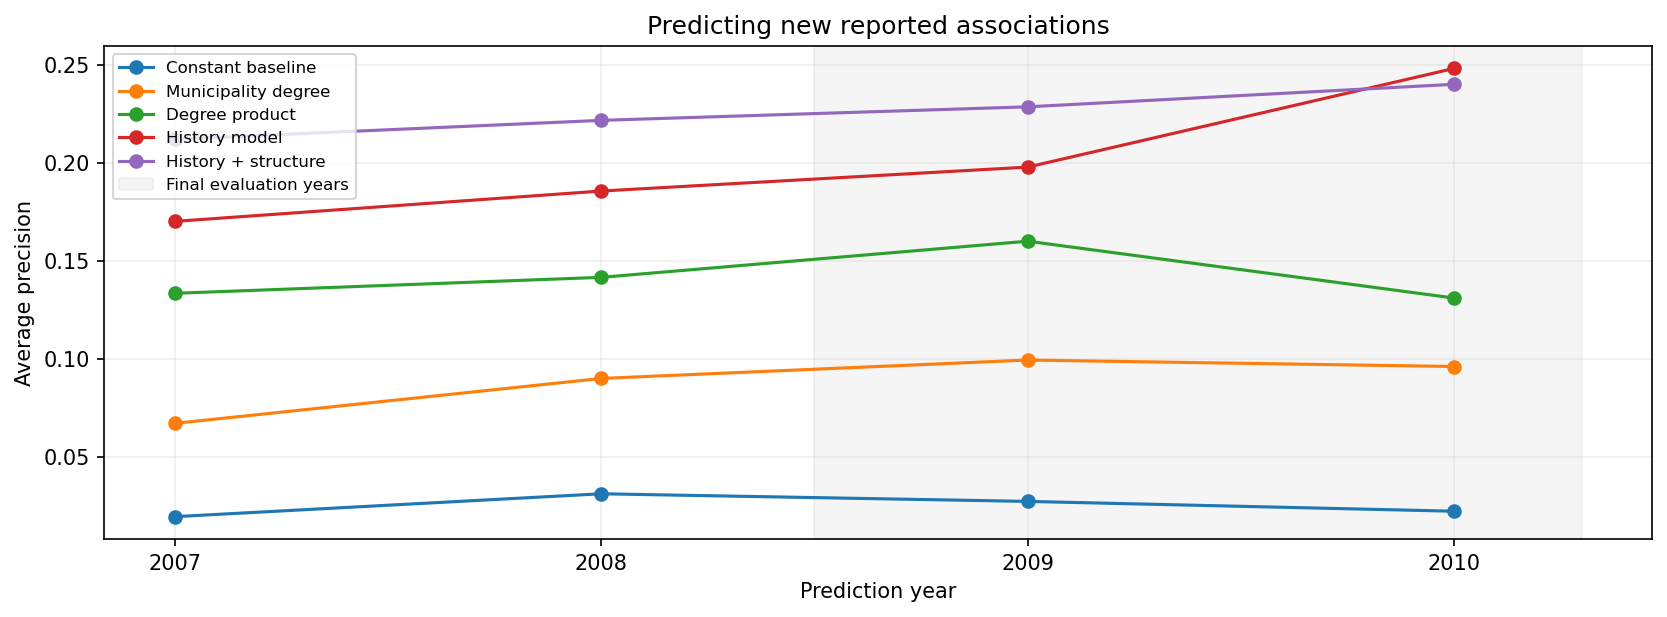

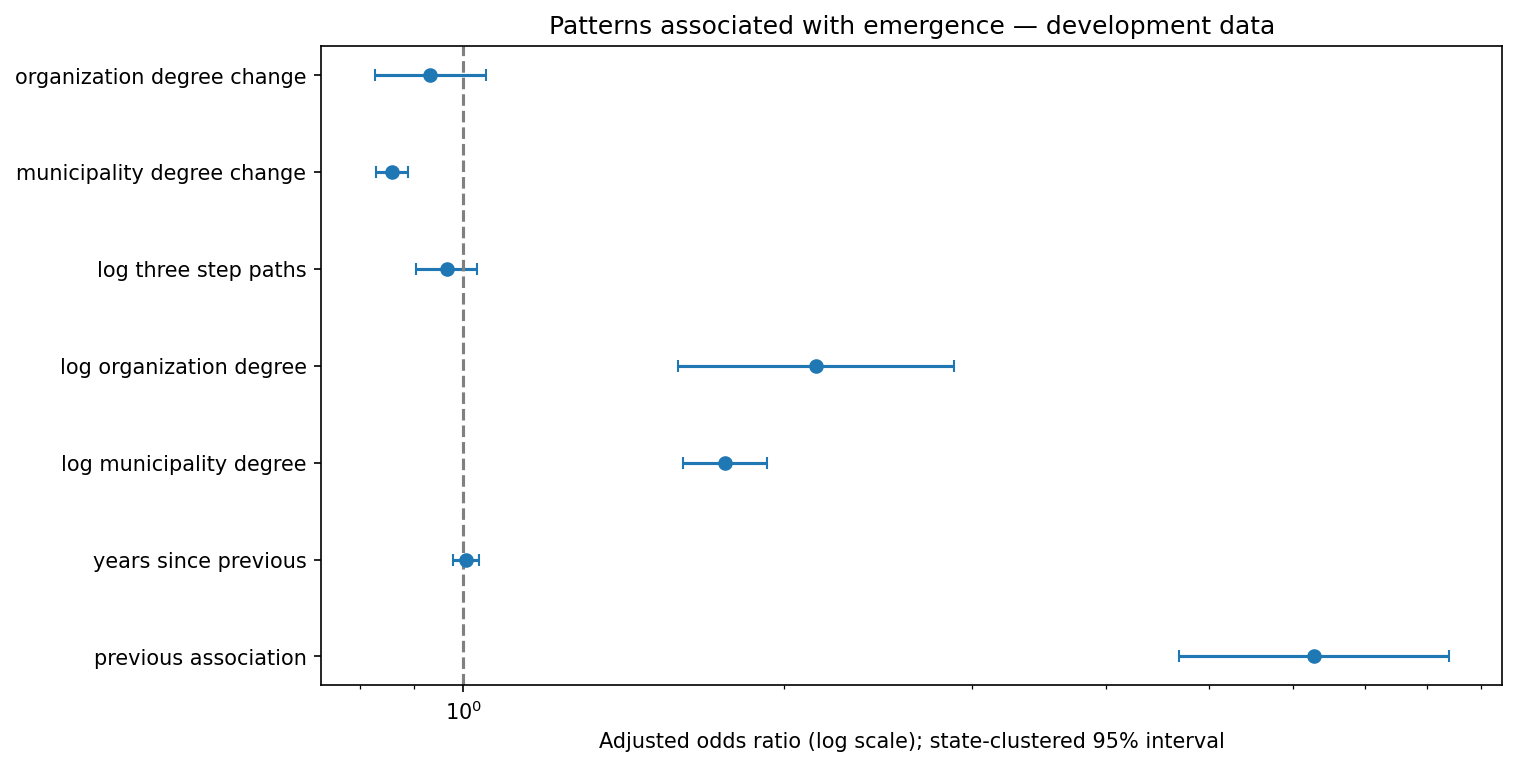

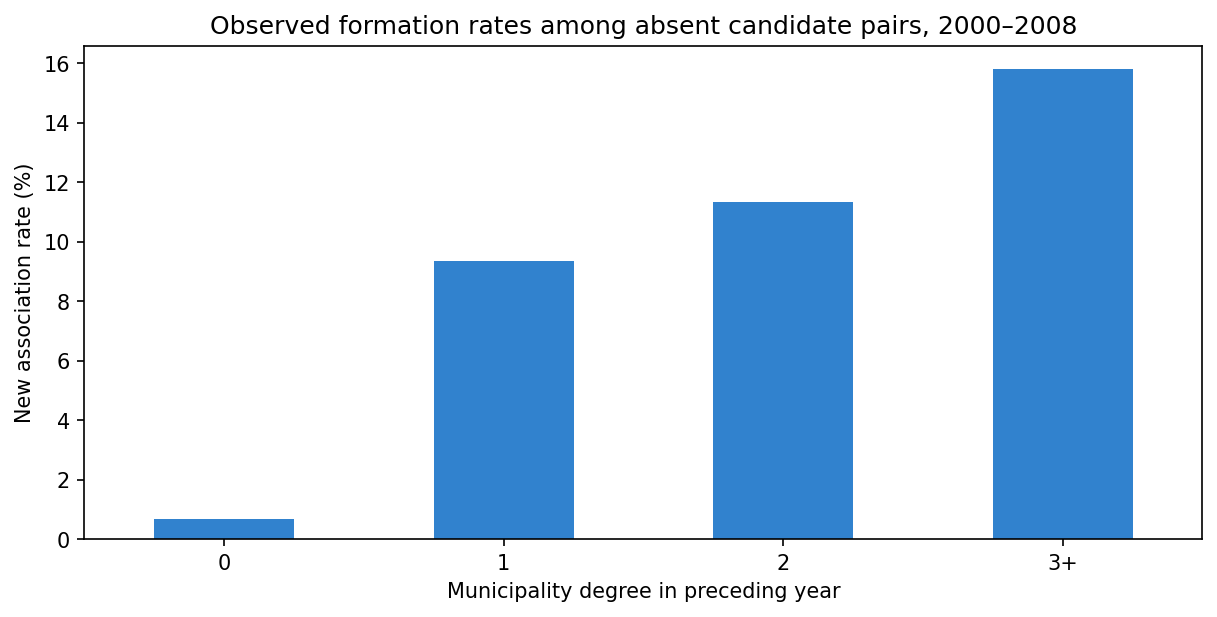

In [13]:
# Model comparison across development and final prediction years.
main_results = evaluation_results[evaluation_results["scenario"] == "Main"]
fig, ax = plt.subplots(figsize=(11, 4), constrained_layout=True)
for label, group in main_results.groupby("model", sort=False):
    ax.plot(group["year"], group["average_precision"], marker="o", label=label)
ax.axvspan(2008.5, 2010.3, color="gray", alpha=0.08, label="Final evaluation years")
ax.set(title="Predicting new reported associations", xlabel="Prediction year", ylabel="Average precision", xticks=[2007, 2008, 2009, 2010])
ax.legend(fontsize=8, loc="best")
ax.grid(alpha=0.2)
show_presentation_figure(fig)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
positions = np.arange(len(effect_results))
ax.errorbar(effect_results["odds_ratio"], positions,
    xerr=np.vstack([effect_results["odds_ratio"] - effect_results["95_lower"],
                   effect_results["95_upper"] - effect_results["odds_ratio"]]), fmt="o", capsize=3)
ax.axvline(1, color="gray", linestyle="--")
ax.set(yticks=positions, yticklabels=effect_results["feature"].str.replace("_", " "),
    xlabel="Adjusted odds ratio (log scale); state-clustered 95% interval",
    title="Patterns associated with emergence — development data", xscale="log")
show_presentation_figure(fig)

fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
(100 * formation_rates["formation_rate"]).plot.bar(ax=ax, color="#3182ce", rot=0)
ax.set(xlabel="Municipality degree in preceding year", ylabel="New association rate (%)",
    title="Observed formation rates among absent candidate pairs, 2000–2008")
show_presentation_figure(fig)

## Research results: Name : value

Final-year AP gains are compared with the history model using paired state-block bootstrap intervals. An interval spanning zero does not establish a clear improvement under this uncertainty calculation. Check comparisons against both degree baselines as well. Sensitivity findings and year-to-year consistency matter; a positive coefficient or predictive gain does not identify a causal mechanism.

In [14]:
for year, row in eligibility_summary.iterrows():
    for name, value in row.items(): print_presentation_value(f"Research {year} {name.replace('_', ' ')}", value)
for _, row in evaluation_results.iterrows():
    for name in ["candidates", "positives", "formation_rate", "average_precision", "precision_at_100", "recall_at_100"]:
        print_presentation_value(f"{row['scenario']} {row['year']} {row['model']} {name.replace('_', ' ')}", row[name])
for year, row in prediction_uncertainty.iterrows():
    for name, value in row.items(): print_presentation_value(f"Final {year} {name.replace('_', ' ')}", value)
for _, row in effect_results.iterrows():
    for name in ["odds_ratio", "95_lower", "95_upper"]:
        print_presentation_value(f"Development {row['feature']} {name}", row[name])
for degree, row in formation_rates.iterrows():
    for name, value in row.items(): print_presentation_value(f"Degree {degree} {name.replace('_', ' ')}", value)
print_presentation_value("Inferential model converged", association_model.converged)
print_presentation_value("Inferential state clusters", inference_data['state'].nunique())

Research 1991 eligible pairs : 0
Research 1991 new links : 0
Research 1991 positives excluded unobserved organization : 6
Research 1992 eligible pairs : 4908
Research 1992 new links : 1
Research 1992 positives excluded unobserved organization : 5
Research 1993 eligible pairs : 9822
Research 1993 new links : 19
Research 1993 positives excluded unobserved organization : 2
Research 1994 eligible pairs : 12261
Research 1994 new links : 25
Research 1994 positives excluded unobserved organization : 0
Research 1995 eligible pairs : 12254
Research 1995 new links : 15
Research 1995 positives excluded unobserved organization : 0
Research 1996 eligible pairs : 12262
Research 1996 new links : 27
Research 1996 positives excluded unobserved organization : 1
Research 1997 eligible pairs : 14706
Research 1997 new links : 41
Research 1997 positives excluded unobserved organization : 1
Research 1998 eligible pairs : 17148
Research 1998 new links : 37
Research 1998 positives excluded unobserved organizat

## Initial interpretation

- In the main analysis, history plus structure outperforms the municipality-degree and degree-product baselines on average precision in both final years.
- Relative to the history model, its AP gain is about **+0.031 in 2009** and **−0.008 in 2010**. Both paired state-bootstrap intervals include zero, so this analysis does not establish a consistent incremental benefit from adding these structural features.
- The history-only model has higher precision@100 in both final years. The answer depends partly on whether the goal is overall ranking or the highest-ranked predictions.
- Development-data associations show higher odds for previously recorded pairs and for greater municipality and organization degrees. The adjusted three-step-path interval includes an odds ratio of one. These patterns are conditional associations, not causes.
- Main results include reappearances. Consult the first-observed-only and `Otros` sensitivity results before generalizing to genuinely unseen pairs. Observed emergence can reflect changes in media reporting.

These are initial results from a fixed, modest model set. Do not tune on the final years and then describe those same years as an untouched evaluation.